<a href="https://colab.research.google.com/github/joaolira00/portfolio-processamento-de-imagens/blob/main/2BIM/Portfolio2_2BIM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [3]:
def segmentar(imagem, tamanho_bloco=101, constante=-10, area_minima=500, inverter=False):
    imagem_suavizada = cv2.GaussianBlur(imagem, (5, 5), 0)

    modo_limiar = cv2.THRESH_BINARY_INV if inverter else cv2.THRESH_BINARY
    mascara_binaria = cv2.adaptiveThreshold(
        imagem_suavizada, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        modo_limiar, tamanho_bloco, constante
    )

    todos_contornos, _ = cv2.findContours(
        mascara_binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    contornos_validos = [c for c in todos_contornos if cv2.contourArea(c) > area_minima]

    mapa_semantico = np.zeros(imagem.shape, np.uint8)
    cv2.drawContours(mapa_semantico, contornos_validos, -1, 255, -1)

    mapa_instancias = np.zeros(imagem.shape, np.int32)
    for indice, contorno in enumerate(contornos_validos):
        cv2.drawContours(mapa_instancias, [contorno], -1, indice + 1, -1)

    return mapa_semantico, mapa_instancias, len(contornos_validos)


def colorir(mapa_instancias):
    total_instancias = mapa_instancias.max()
    imagem_colorida = np.zeros((*mapa_instancias.shape, 3), np.uint8)

    paleta = plt.get_cmap('nipy_spectral')(
        np.linspace(0.1, 0.95, max(total_instancias, 1))
    )[:, :3]
    paleta = paleta[np.random.default_rng(0).permutation(total_instancias)]

    for indice in range(total_instancias):
        imagem_colorida[mapa_instancias == indice + 1] = (paleta[indice] * 255).astype(np.uint8)

    return imagem_colorida


def comparar(imagem, **parametros):
    mapa_semantico, mapa_instancias, total_objetos = segmentar(imagem, **parametros)

    paineis = [
        (imagem, 'Entrada'),
        (mapa_semantico, 'Semântica (1 classe: objeto)'),
        (colorir(mapa_instancias), f'Instância (1 cor por objeto): {total_objetos}'),
    ]

    plt.figure(figsize=(15, 4))
    for posicao, (conteudo, titulo) in enumerate(paineis, start=1):
        plt.subplot(1, 3, posicao)
        plt.imshow(conteudo, cmap='gray')
        plt.title(titulo)
        plt.axis('off')
    plt.show()

    return total_objetos

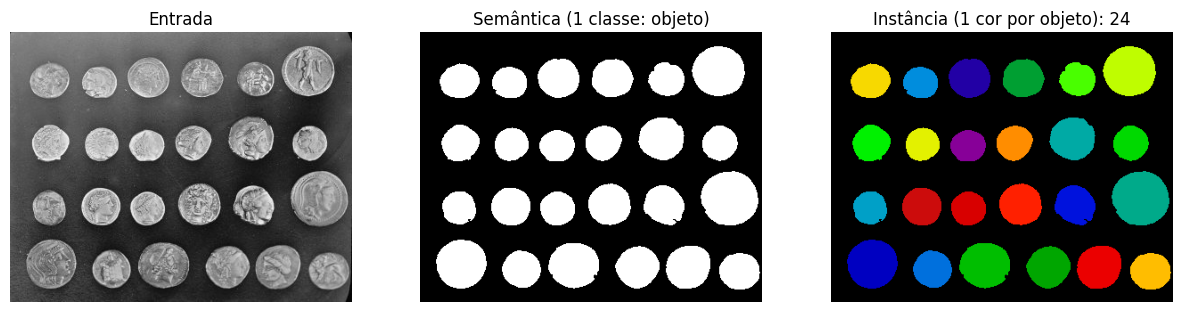

In [4]:
n_moedas = comparar(data.coins())

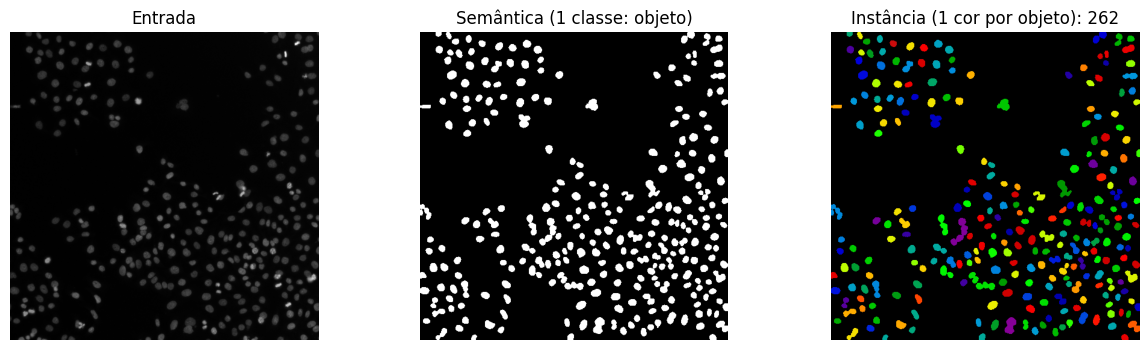

In [7]:
n_nucleos = comparar(data.human_mitosis(), tamanho_bloco=51, constante=-5, area_minima=50, inverter=False)